# Phát hiện chi tiêu bất thường dựa trên hành vi (Model B) với Apache Spark và HDFS

Notebook này là phần phân tích dữ liệu và đánh giá mô hình của đồ án. Nó chạy trên cụm Docker của nhóm:

- **Lưu trữ:** HDFS (namenode + datanode), dữ liệu gốc ở `hdfs://namenode:8020/data/...`
- **Xử lý:** Spark standalone (`spark://spark-master:7077`), đọc thẳng từ HDFS
- **Huấn luyện:** `train_behavior.py` (Model B) và `train_pipeline.py` (Model A), chạy bằng `scripts/train_on_cluster.sh`

Hệ thống dùng **hai mô hình**:

| | Model A (benchmark) | Model B (triển khai trong app) |
|---|---|---|
| Dữ liệu | Kaggle Credit Card Fraud, 284.807 dòng, `V1..V28` là PCA ẩn danh | Sparkov, 1.852.394 giao dịch của 983 chủ thẻ |
| Mục đích | Đánh giá kỹ thuật xử lý mất cân bằng trên benchmark chuẩn | Cảnh báo chi tiêu bất thường so với thói quen trên app |
| Feature | 30 feature ngân hàng (app không có) | 7 feature hành vi, app tính được từ lịch sử hóa đơn |

Lý do cần Model B được chứng minh bằng số liệu ở mục 6: app chỉ có số tiền và thời gian, nên nếu dùng Model A thì phải điền 0 cho `V1..V28`, và khi đó Model A gần như không phát hiện được gì.

In [1]:
import glob, json, sys
from pathlib import Path
sys.path[:0] = ['/opt/spark/python', *glob.glob('/opt/spark/python/lib/py4j-*.zip'), '/workspace']

import matplotlib
import matplotlib.pyplot as plt
import pandas as pd
from IPython.display import display
from pyspark.sql import SparkSession, functions as F

from behavior_features import FEATURE_COLUMNS, SPARKOV_CATEGORIES
from behavior_features_spark import build_features, read_sparkov, scorable

%matplotlib inline
plt.rcParams.update({'figure.figsize': (9, 4), 'axes.grid': True, 'grid.alpha': 0.3, 'axes.spines.top': False, 'axes.spines.right': False})
NORMAL, FRAUD = '#4C78A8', '#E45756'

spark = (SparkSession.builder.appName('BehaviorAnomalyNotebook')
         .master('spark://spark-master:7077')
         .config('spark.executor.memory', '2560m')
         .config('spark.sql.session.timeZone', 'UTC')
         .config('spark.sql.shuffle.partitions', '48')
         .getOrCreate())
spark.sparkContext.setLogLevel('ERROR')
print('Spark', spark.version, '| master', spark.sparkContext.master)

Using Spark's default log4j profile: org/apache/spark/log4j2-defaults.properties
Setting default log level to "WARN".
To adjust logging level use sc.setLogLevel(newLevel). For SparkR, use setLogLevel(newLevel).


26/10/07 12:54:47 WARN NativeCodeLoader: Unable to load native-hadoop library for your platform... using builtin-java classes where applicable


Spark 4.0.1 | master spark://spark-master:7077


## 1. Dữ liệu trên HDFS

Spark đọc hai file CSV trực tiếp từ HDFS với schema khai báo tường minh (không dùng `inferSchema`, tránh phải quét file 2 lần). Chỉ giữ các cột mà app cũng có được: thời gian, chủ thẻ, danh mục, số tiền và nhãn. Các cột như tọa độ, nghề nghiệp, ngày sinh bị loại vì app không bao giờ có.

In [2]:
HDFS = 'hdfs://namenode:8020/data/sparkov'
raw = read_sparkov(spark, f'{HDFS}/fraudTrain.csv', 'train').unionByName(read_sparkov(spark, f'{HDFS}/fraudTest.csv', 'test')).cache()
jvm = spark.sparkContext._jvm
fs = jvm.org.apache.hadoop.fs.FileSystem.get(jvm.java.net.URI(HDFS), spark.sparkContext._jsc.hadoopConfiguration())
for status in fs.listStatus(jvm.org.apache.hadoop.fs.Path(HDFS)):
    print(f"{status.getPath().toString():60s} {status.getLen() / 1024**2:8.1f} MB  block size {status.getBlockSize() / 1024**2:.0f} MB")
print('Số partition khi đọc:', raw.rdd.getNumPartitions())
summary = raw.groupBy('source').agg(F.count('*').alias('rows'), F.sum('label').cast('int').alias('fraud'), F.countDistinct('cc_num').alias('users')).toPandas()
summary['fraud_rate_%'] = (summary['fraud'] / summary['rows'] * 100).round(3)
display(summary)

hdfs://namenode:8020/data/sparkov/fraudTest.csv                 143.4 MB  block size 128 MB
hdfs://namenode:8020/data/sparkov/fraudTrain.csv                335.0 MB  block size 128 MB


Số partition khi đọc: 8


,source,rows,fraud,users,fraud_rate_%
0,test,555719,2145,924,0.386
1,train,1296675,7506,983,0.579


## 2. Mất cân bằng dữ liệu và hành vi gian lận

Tỉ lệ gian lận chỉ khoảng 0,5%, nên accuracy không có ý nghĩa (đoán "bình thường" cho tất cả đã đạt 99,5%). Vì vậy mô hình được đánh giá bằng Precision, Recall, F1 và PR-AUC.

Các biểu đồ dưới đây được tính bằng Spark (groupBy trên 1,85 triệu dòng); chỉ kết quả tổng hợp vài chục dòng được đưa về để vẽ.

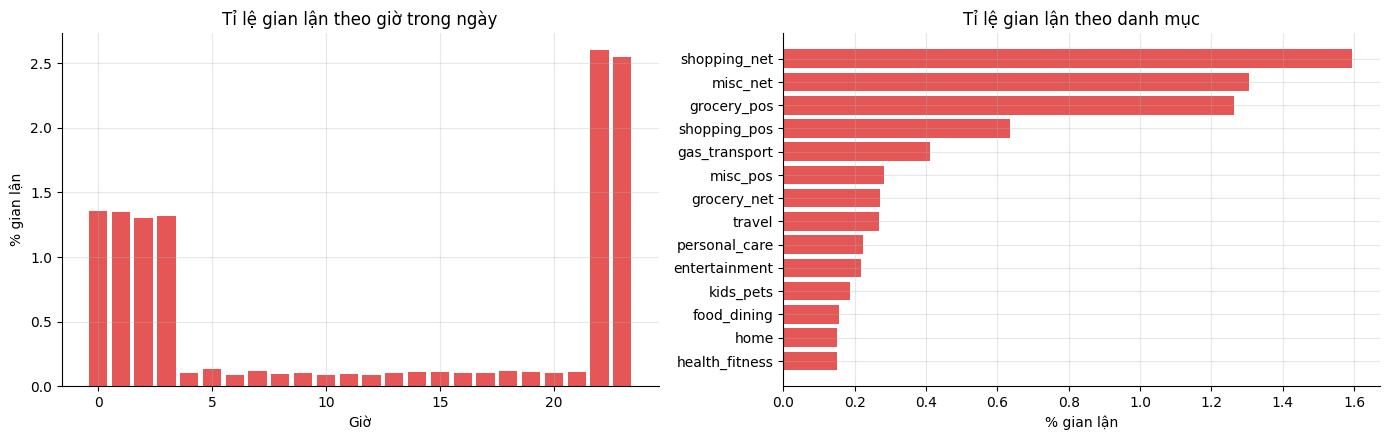

In [3]:
by_hour = (raw.withColumn('hour', F.hour(F.to_timestamp('trans_date_trans_time')))
           .groupBy('hour').agg(F.avg('label').alias('fraud_rate'), F.count('*').alias('rows')).orderBy('hour').toPandas())
by_category = raw.groupBy('category').agg(F.avg('label').alias('fraud_rate')).orderBy('fraud_rate').toPandas()

fig, axes = plt.subplots(1, 2, figsize=(14, 4.5))
axes[0].bar(by_hour['hour'], by_hour['fraud_rate'] * 100, color=FRAUD)
axes[0].set(title='Tỉ lệ gian lận theo giờ trong ngày', xlabel='Giờ', ylabel='% gian lận')
axes[1].barh(by_category['category'], by_category['fraud_rate'] * 100, color=FRAUD)
axes[1].set(title='Tỉ lệ gian lận theo danh mục', xlabel='% gian lận')
plt.tight_layout(); plt.show()

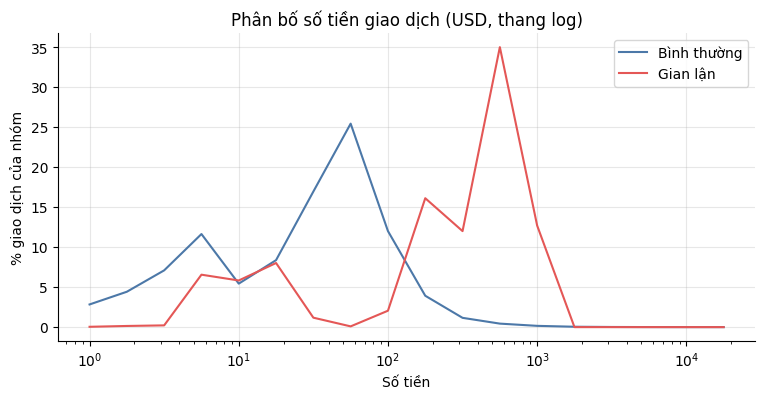

In [4]:
amount = (raw.withColumn('bucket', F.floor(F.log10('amt') * 4) / 4)
          .groupBy('label', 'bucket').count().toPandas())
pivot = amount.pivot(index='bucket', columns='label', values='count').fillna(0)
pivot = pivot / pivot.sum()
fig, ax = plt.subplots()
ax.plot(10 ** pivot.index, pivot[0.0] * 100, color=NORMAL, label='Bình thường')
ax.plot(10 ** pivot.index, pivot[1.0] * 100, color=FRAUD, label='Gian lận')
ax.set(xscale='log', title='Phân bố số tiền giao dịch (USD, thang log)', xlabel='Số tiền', ylabel='% giao dịch của nhóm')
ax.legend(); plt.show()

Nhận xét: giao dịch gian lận tập trung vào ban đêm, ở một số danh mục mua sắm và tạp hóa, và có số tiền lớn hơn hẳn giao dịch bình thường. Nhưng số tiền tuyệt đối phụ thuộc vào từng người và từng đơn vị tiền tệ, nên mô hình không dùng số tiền tuyệt đối mà dùng **tỉ lệ so với thói quen của chính người đó**.

## 3. Feature hành vi bằng Spark Window functions

Với mỗi giao dịch, Spark gom tối đa 100 giao dịch trước đó của cùng chủ thẻ (`Window.partitionBy('cc_num').orderBy('ts').rowsBetween(-101, -1)`), chỉ giữ các giao dịch có thời điểm nhỏ hơn hẳn, rồi tính 7 feature:

| Feature | Ý nghĩa |
|---|---|
| `hour`, `day_of_week` | Giờ và thứ của giao dịch |
| `category_idx` | Danh mục (14 nhóm Sparkov; app ánh xạ tên danh mục tiếng Việt sang nhóm này) |
| `amt_ratio_user` | Số tiền chia trung bình 100 giao dịch gần nhất của người đó |
| `amt_ratio_user_cat` | Số tiền chia trung bình các giao dịch cùng danh mục trong 100 giao dịch đó |
| `txn_count_24h` | Số giao dịch trong 24 giờ trước |
| `secs_since_prev` | Số giây kể từ giao dịch trước |

Con số 100 khớp với lượng lịch sử app lấy được từ backend, nên feature lúc huấn luyện và lúc dự đoán trên app được tính trên cùng một lượng dữ liệu. Giao dịch có ít hơn 5 giao dịch trước đó (người dùng mới) không được chấm điểm, ở cả lúc huấn luyện lẫn trên app.

In [5]:
featured = scorable(build_features(raw)).select('label', 'source', *FEATURE_COLUMNS).cache()
print('Giao dịch đủ lịch sử để chấm điểm:', featured.count())
display(featured.groupBy('label').agg(*[F.round(F.expr(f'percentile_approx({c}, 0.5)'), 2).alias(f'median_{c}') for c in FEATURE_COLUMNS]).toPandas())

Giao dịch đủ lịch sử để chấm điểm: 1847399


,label,median_hour,median_day_of_week,median_category_idx,median_amt_ratio_user,median_amt_ratio_user_cat,median_txn_count_24h,median_secs_since_prev
0,1.0,22.0,3.0,8.0,4.94,2.87,4.0,4881.0
1,0.0,14.0,3.0,6.0,0.67,0.88,3.0,15721.0


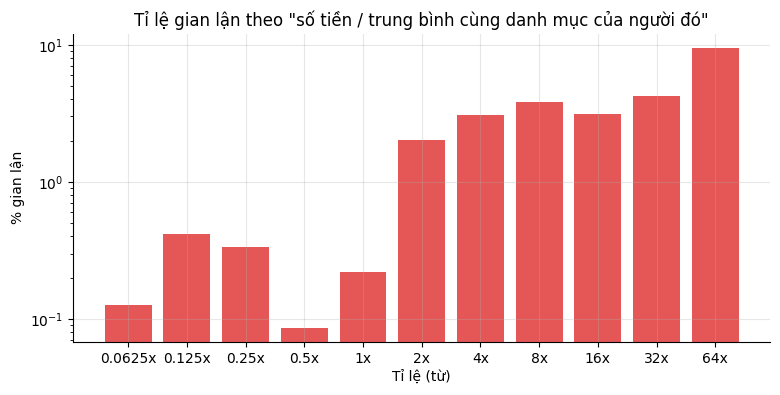

In [6]:
ratio = (featured.withColumn('bucket', F.least(F.floor(F.log2(F.greatest('amt_ratio_user_cat', F.lit(0.0625)))), F.lit(6)))
         .groupBy('bucket').agg(F.avg('label').alias('fraud_rate'), F.count('*').alias('rows')).orderBy('bucket').toPandas())
labels = [f'{2.0 ** b:g}x' for b in ratio['bucket']]
fig, ax = plt.subplots()
ax.bar(labels, ratio['fraud_rate'] * 100, color=FRAUD)
ax.set(title='Tỉ lệ gian lận theo "số tiền / trung bình cùng danh mục của người đó"', xlabel='Tỉ lệ (từ)', ylabel='% gian lận', yscale='log')
plt.show()

Tỉ lệ gian lận tăng mạnh khi giao dịch vượt xa mức chi tiêu thường ngày của chính người đó. Đây là tín hiệu mà app thật sự tính được từ lịch sử hóa đơn.

## 4. Huấn luyện và so sánh mô hình

`train_behavior.py` chia dữ liệu **theo thời gian** (không xáo trộn ngẫu nhiên, để không dùng tương lai dự đoán quá khứ):

- train: 90% đầu của `fraudTrain`; validation: 10% cuối của `fraudTrain`; test: toàn bộ `fraudTest` (giai đoạn sau);
- xử lý mất cân bằng bằng **class weights** (trọng số lớp gian lận = số giao dịch bình thường / số giao dịch gian lận), không nhân bản dữ liệu;
- so sánh **Random Forest** và **Gradient-Boosted Trees** của Spark MLlib, cùng một **luật cơ sở** (số tiền >= 3 lần trung bình cùng danh mục);
- chọn mô hình có PR-AUC trên validation cao hơn, chọn ngưỡng cảnh báo cho F1 lớn nhất trên validation, rồi mới đo trên test.

In [7]:
metrics = json.loads(Path('/workspace/artifacts/behavior/metrics_behavior.json').read_text())
rows = []
for name, result in metrics['candidates'].items():
    test = result['test']
    rows.append({'model': name, 'PR-AUC (val)': result['validation']['areaUnderPR'], 'PR-AUC (test)': test['areaUnderPR'],
                 'ROC-AUC (test)': test['areaUnderROC'], 'threshold': test['threshold'], 'precision': test['precision'],
                 'recall': test['recall'], 'f1': test['f1'], 'train (s)': result['trainSeconds']})
rule = metrics['ruleBaseline']
rows.append({'model': 'rule: ' + rule['rule'], 'precision': rule['precision'], 'recall': rule['recall'], 'f1': rule['f1']})
table = pd.DataFrame(rows).set_index('model')
display(table.round(4))
print('Mô hình được chọn:', metrics['chosenAlgorithm'], '| version', metrics['modelVersion'])
print('Số dòng:', json.dumps(metrics['split']), '| bỏ vì cold start:', metrics['coldStartDropped'])

,PR-AUC (val),PR-AUC (test),ROC-AUC (test),threshold,precision,recall,f1,train (s)
model,,,,,,,,
random_forest,0.7004,0.6155,0.9896,0.943,0.6095,0.6077,0.6086,150.2
gbt,0.7539,0.6539,0.9904,0.961,0.5914,0.6707,0.6285,123.7
rule: amt_ratio_user_cat >= 3.0,NaN,NaN,NaN,NaN,0.0267,0.4915,0.0507,NaN


Mô hình được chọn: gbt | version behavior-gbt-2026-10-07
Số dòng: {"validationCutoff": "2020-05-02T14:52:07+00:00", "trainRows": 1162460, "trainFraud": 6333, "validationRows": 129300, "testRows": 555639} | bỏ vì cold start: 4995


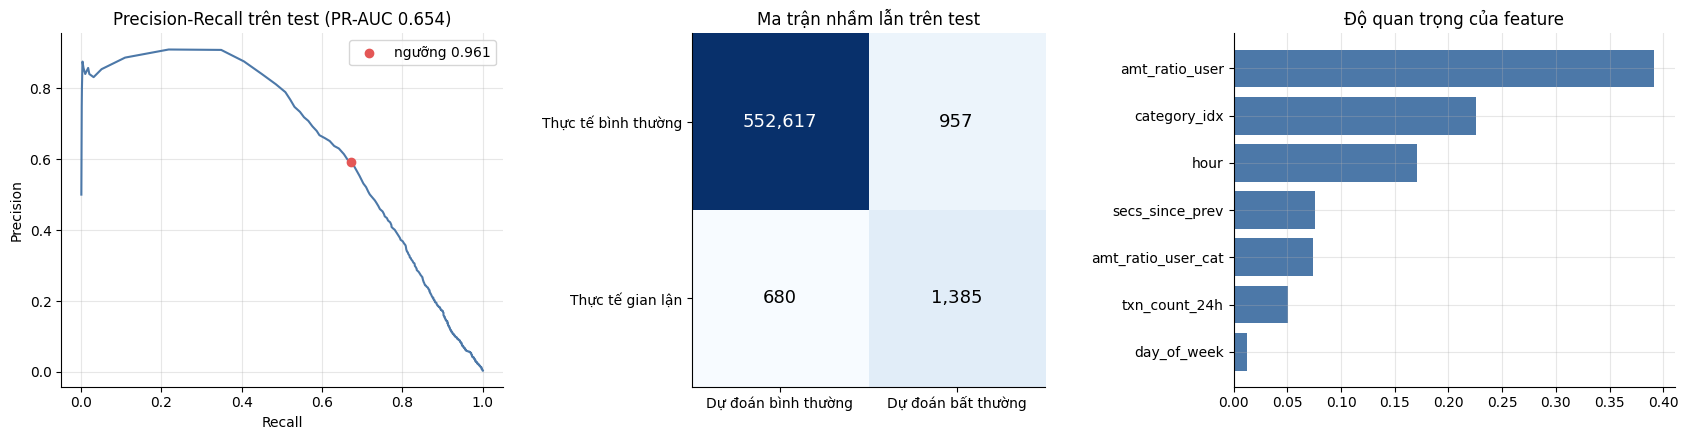

In [8]:
chosen = metrics['candidates'][metrics['chosenAlgorithm']]
curve = pd.DataFrame(json.loads(Path('/workspace/artifacts/behavior/pr_curve_test.json').read_text()))
test = chosen['test']
fig, axes = plt.subplots(1, 3, figsize=(17, 4.5))
axes[0].plot(curve['recall'], curve['precision'], color=NORMAL)
axes[0].scatter([test['recall']], [test['precision']], color=FRAUD, zorder=3, label=f"ngưỡng {test['threshold']:.3f}")
axes[0].set(title=f"Precision-Recall trên test (PR-AUC {test['areaUnderPR']:.3f})", xlabel='Recall', ylabel='Precision'); axes[0].legend()

matrix = [[test['trueNegative'], test['falsePositive']], [test['falseNegative'], test['truePositive']]]
axes[1].imshow(matrix, cmap='Blues', norm=matplotlib.colors.LogNorm())
for i in range(2):
    for j in range(2):
        axes[1].text(j, i, f'{matrix[i][j]:,}', ha='center', va='center', fontsize=13, color='white' if matrix[i][j] > 100000 else 'black')
axes[1].set(xticks=[0, 1], yticks=[0, 1], xticklabels=['Dự đoán bình thường', 'Dự đoán bất thường'], yticklabels=['Thực tế bình thường', 'Thực tế gian lận'], title='Ma trận nhầm lẫn trên test'); axes[1].grid(False)

importance = pd.Series(chosen['featureImportances']).sort_values()
axes[2].barh(importance.index, importance.values, color=NORMAL)
axes[2].set(title='Độ quan trọng của feature')
plt.tight_layout(); plt.show()

## 5. Ý nghĩa với người dùng app

Ngưỡng cảnh báo được chọn trên validation để cân bằng giữa bỏ sót và báo nhầm. Tỉ lệ giao dịch bị cảnh báo (`flaggedShare`) cho biết người dùng sẽ thấy hộp thoại cảnh báo thường xuyên đến mức nào: nếu quá cao thì người dùng sẽ bỏ qua cảnh báo.

In [9]:
print(f"Tỉ lệ giao dịch bị cảnh báo trên test: {test['flaggedShare'] * 100:.2f}%")
print(f"Trong số giao dịch bị cảnh báo, {test['precision'] * 100:.1f}% là gian lận thật; phát hiện được {test['recall'] * 100:.1f}% số giao dịch gian lận.")

Tỉ lệ giao dịch bị cảnh báo trên test: 0.42%
Trong số giao dịch bị cảnh báo, 59.1% là gian lận thật; phát hiện được 67.1% số giao dịch gian lận.


## 6. Model A và thí nghiệm "điền 0 cho V1..V28"

Model A (Random Forest với class weights trên Kaggle Credit Card) được huấn luyện lại trên cùng cụm, đọc từ `hdfs://namenode:8020/data/creditcard/creditcard.csv`. Thí nghiệm: giữ nguyên các dòng test nhưng thay `V1..V28` bằng 0, đúng như một app chỉ biết số tiền và thời gian sẽ phải gửi.

,Đủ 30 feature,V1..V28 = 0
precision,0.3648,0.0
recall,0.7946,0.0
f1,0.5000,0.0


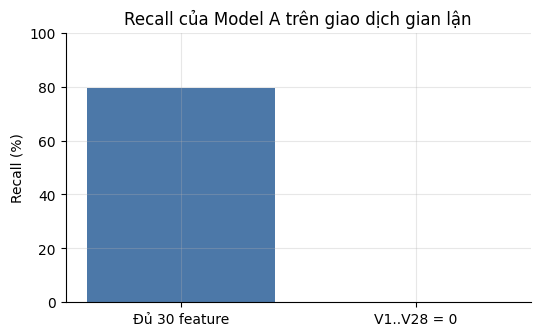

Khi điền 0, Model A gắn cờ 0.000% giao dịch test và phát hiện 0 trên 112 giao dịch gian lận.


In [10]:
model_a = json.loads(Path('/workspace/metrics.json').read_text())
ablation = model_a['zeroPcaAblation']
display(pd.DataFrame({'Đủ 30 feature': {k: model_a[k] for k in ('precision', 'recall', 'f1')},
                      'V1..V28 = 0': {k: ablation[k] for k in ('precision', 'recall', 'f1')}}).round(4))
fig, ax = plt.subplots(figsize=(6, 3.5))
ax.bar(['Đủ 30 feature', 'V1..V28 = 0'], [model_a['recall'] * 100, ablation['recall'] * 100], color=[NORMAL, FRAUD])
ax.set(title='Recall của Model A trên giao dịch gian lận', ylabel='Recall (%)', ylim=(0, 100))
plt.show()
print(f"Khi điền 0, Model A gắn cờ {ablation['flaggedShare'] * 100:.3f}% giao dịch test và phát hiện {ablation['truePositive']} trên {ablation['truePositive'] + ablation['falseNegative']} giao dịch gian lận.")

Kết luận: điền 0 cho các feature PCA không phải là "imputation" hợp lệ, vì giá trị 0 nằm đúng vùng của giao dịch bình thường. Model A chỉ dùng để đánh giá kỹ thuật trên benchmark; app dùng Model B.

## 7. Kết luận và giới hạn

- Dữ liệu được lưu trên HDFS và xử lý phân tán bằng Spark (window functions, groupBy, MLlib) trên 1,85 triệu giao dịch.
- Model B dùng đúng các feature mà app có, nên cảnh báo trên app là kết quả suy luận thật. API `/v2/predict-anomaly` tính lại feature bằng cùng công thức, và `scripts/e2e_check.py` kiểm tra rằng API tái tạo đúng feature và xác suất của Spark.
- **Giới hạn:** Sparkov là dữ liệu mô phỏng (dữ liệu chi tiêu cá nhân có nhãn không được công khai); thói quen chi tiêu của người dùng Việt Nam có thể khác. Cụm HDFS chỉ có 1 datanode (replication 1) vì chạy trên một máy. Nhãn "fraud" được diễn giải trên app là "chi tiêu lệch khỏi thói quen".

In [11]:
spark.stop()